# Leaf LMA from reflectance spectra with the released Ely et al. 2019 PLSR model

**Paper:** Ely KS, Burnett AC, Lieberman-Cribbin W, Serbin S, Rogers A. (2019)
*Spectroscopy can predict key leaf traits associated with source-sink balance and carbon-nitrogen status.*
**Journal of Experimental Botany** 70(6):1789-1799. [DOI 10.1093/jxb/erz061](https://doi.org/10.1093/jxb/erz061)

**Author code:** [https://github.com/TESTgroup-BNL/Ely_etal_2019_JournalOfExperimentalBotany](https://github.com/TESTgroup-BNL/Ely_etal_2019_JournalOfExperimentalBotany) — GPL-3.0, pinned commit `44face179c5cf17dddd5d7b7487ed0a1485e65f9`.
The notebook applies the **final 12-component LMA spectra-trait PLSR coefficients** released by the authors
(`PLSR_model_coefficients/LMA/`) to fresh-leaf reflectance spectra from two public EcoSIS packages
([LOPEX93](https://ecosis.org/package/13aef0ce-dd6f-4b35-91d9-28932e506c41),
[Angers](https://ecosis.org/package/2231d4f6-981e-4408-bf23-1b2b303f475e)), derives jackknife 95% intervals,
and reproduces the authors' vignette *observed-vs-predicted* validation
(`vignettes/run_lma_plsr_example.Rmd`, rendered in the repo as `run_lma_plsr_example.pdf`).

**Scope (partial demonstration):** this is the authors' own external-data application vignette, executed on their
released model artifacts. It is **not** a reproduction of the paper's dataset-level validation (whose sampling and
split details are not needed for this demo and were not readable from the paywalled full text).

**Execution status:** this notebook was fully executed on a fresh Google Colab **CPU** runtime (see validation record
at the end). No GPU is used or required: the computation is small matrix algebra on ~600 spectra x 1901 wavelengths.

**AI-assisted orchestration statement:** the authors did not provide a Colab notebook. The R code below follows the
authors' vignette step by step, executed with `Rscript` from Python launcher cells. Base-R substitutions for
`readr`/`httr`/`scales` are documented beside the relevant cells; `plotrix::plotCI` is kept as in the original.
The executed example and the checks listed here were validated, but untested behavior is not guaranteed.

**日本語要約:** Ely et al. (2019) の最終 LMA PLSR 係数(著者公開のモデル成果物)を、EcoSIS の公開生葉反射スペクトル
(LOPEX93, Angers) に適用し、ジャックナイフ不確実性付きの LMA 推定と、著者ビネットの観測値対予測値検証を再現します。
実行は CPU のみ(GPU 不要)。著者の R コードを `Rscript` でそのまま実行する構成です。

**References**
- Author vignette (pinned): `https://raw.githubusercontent.com/TESTgroup-BNL/Ely_etal_2019_JournalOfExperimentalBotany/44face179c5cf17dddd5d7b7487ed0a1485e65f9/vignettes/run_lma_plsr_example.pdf`
- Coefficients: `https://raw.githubusercontent.com/TESTgroup-BNL/Ely_etal_2019_JournalOfExperimentalBotany/44face179c5cf17dddd5d7b7487ed0a1485e65f9/PLSR_model_coefficients/LMA/`
- EcoSIS API: `https://ecosis.org/api/package/{id}/export?metadata=true`

## Runtime selection — CPU only (Run all)

Select **Runtime > Change runtime type > CPU** (the default). The workload is linear algebra on a
~600 x 1901 spectra matrix plus ~1000 jackknife repetitions — seconds on CPU. No GPU/CUDA path exists in
the author vignette or this demonstration, so no GPU session is needed.

**日本語:** 「ランタイム > ランタイムのタイプを変更 > CPU」を選択してください。本デモは CPU 数秒の行列計算のみで、GPU は不要です。

**Expected run (measured on the validation run, 2026-10-27, fresh CPU VM):** see the validation record at the end.
Downloads: ~33 MB (jackknife coefficients) + ~10 MB (12-comp coefficients, small) + EcoSIS LOPEX93 and Angers
CSV exports (tens of MB). The next cell checks the runtime and installs the single R package the vignette needs
beyond base R.

In [ ]:
import shutil, subprocess, sys
assert shutil.which("Rscript") is not None, "Rscript not found: this notebook needs Colab's preinstalled R"
r = subprocess.run(["Rscript", "-e", "cat(R.version.string)"], check=True, text=True, capture_output=True)
print(r.stdout)

R version 4.6.1 (2026-06-24)


### R environment and the one required package

The vignette loads `readr`, `scales`, `plotrix`, `httr`, and `devtools`. Only **plotrix** (for the author's
`plotCI` validation plot) is not replaceable by base R without altering the plotting code, so this notebook
installs exactly that package from CRAN. `readr`/`httr`/`scales`/`devtools` are not needed: file reads and
downloads use base R (`read.csv`, `download.file`) and transparency is set with an explicit RGBA color code.
This is a documented compatibility adaptation — the numerical operations are unchanged.

**日本語:** ビネットが必要とするパッケージのうち、検証図の `plotCI` のための `plotrix` のみをインストールします。
残りはベース R の関数で等価に置き換えています(数値計算は不変)。

In [ ]:
import pathlib, subprocess

def run_r(script_name: str, code: str, timeout: float = 1800.0) -> None:
    """Write an R script under /content and execute it with the preinstalled Rscript."""
    path = pathlib.Path("/content") / script_name
    path.write_text(code)
    subprocess.run(["Rscript", str(path)], check=True, timeout=timeout)

run_r("01_setup.R", r'''
cat("R version:", R.version.string, "\n")
if (!requireNamespace("plotrix", quietly = TRUE)) {
  install.packages("plotrix", repos = "https://cloud.r-project.org")
}
library(plotrix)
cat("plotrix version:", as.character(packageVersion("plotrix")), "\n")
''')

### PLSR model artifacts (the authors' released trained coefficients)

Download the final 12-component LMA PLSR coefficients and the matching jackknife coefficient table from the
pinned author commit. These are the **trained-model artifacts** of the paper (the released "weights"): the 12-comp
file is a small table of 1902 rows (intercept + 1901 wavelengths) x 2 columns; the jackknife table holds one
intercept + coefficient vector per resampling iteration (~33 MB). Expected result: row/column counts printed
and both tables cached as an RDS file for later cells.

**日本語:** 著者が公開した学習済み LMA PLSR 係数(12成分)とジャックナイフ係数表をピン留したコミットから取得し、
行数・列数を確認して RDS に保存します。

In [ ]:
run_r("02_coeffs.R", r'''
# Pinned author code repo: TESTgroup-BNL/Ely_etal_2019_JournalOfExperimentalBotany
# commit 44face179c5cf17dddd5d7b7487ed0a1485e65f9
base_url <- "https://raw.githubusercontent.com/TESTgroup-BNL/Ely_etal_2019_JournalOfExperimentalBotany/44face179c5cf17dddd5d7b7487ed0a1485e65f9/PLSR_model_coefficients/LMA"
dl <- function(url, dest, tries = 3) {
  for (i in seq_len(tries)) {
    r <- tryCatch({ download.file(url, dest, mode = "wb", quiet = TRUE); TRUE },
                  error = function(e) FALSE)
    if (isTRUE(r) && file.exists(dest) && file.info(dest)$size > 0) {
      cat(sprintf("downloaded %s (%d bytes)\n", dest, file.info(dest)$size))
      return(invisible(TRUE))
    }
    Sys.sleep(2)
  }
  stop("download failed after retries: ", url)
}
dl(file.path(base_url, "LMA_g_m2_PLSR_Coefficients_12comp.csv"),
   "/content/LMA_g_m2_PLSR_Coefficients_12comp.csv")
dl(file.path(base_url, "LMA_g_m2_Jackkife_PLSR_Coefficients.csv"),
   "/content/LMA_g_m2_Jackkife_PLSR_Coefficients.csv")
coeffs <- read.csv("/content/LMA_g_m2_PLSR_Coefficients_12comp.csv")
jk <- read.csv("/content/LMA_g_m2_Jackkife_PLSR_Coefficients.csv")
cat("12-comp coefficient table dims (rows, cols):", dim(coeffs), "\n")
cat("jackknife coefficient table dims (rows, cols):", dim(jk), "\n")
cat("first coefficient-table row (author vignette: row 1 is the intercept):\n")
print(coeffs[1, ])
saveRDS(list(coeffs = coeffs, jk = jk), "/content/plsr_coeffs.rds")
''')

### EcoSIS reflectance-trait packages (LOPEX93 and Angers)

Download the two public EcoSIS packages used by the author vignette through its documented export API
(`GET /api/package/{id}/export?metadata=true`, CSV bytes). LOPEX93 package id `13aef0ce-dd6f-4b35-91d9-28932e506c41`;
Angers id `2231d4f6-981e-4408-bf23-1b2b303f475e`. Each export bundles metadata columns plus one reflectance column
per 1-nm wavelength (`500`...`2400`, read by base R as `X500`...`X2400`). Expected result: row/column counts and
spectra-column checks for both packages.

**日本語:** ビネットが使う 2 つの公開 EcoSIS パッケージ(LOPEX93, Angers)を公式 API から CSV で取得し、
サイズと波長列(X500-X2400)の有無を確認します。

In [ ]:
run_r("03_ecosis.R", r'''
dl <- function(url, dest, tries = 3) {
  for (i in seq_len(tries)) {
    r <- tryCatch({ download.file(url, dest, mode = "wb", quiet = TRUE); TRUE },
                  error = function(e) FALSE)
    if (isTRUE(r) && file.exists(dest) && file.info(dest)$size > 0) {
      cat(sprintf("downloaded %s (%d bytes)\n", dest, file.info(dest)$size))
      return(invisible(TRUE))
    }
    Sys.sleep(2)
  }
  stop("download failed after retries: ", url)
}
ecosis_export <- function(id, dest) {
  dl(sprintf("https://ecosis.org/api/package/%s/export?metadata=true", id), dest)
  read.csv(dest, check.names = TRUE, stringsAsFactors = FALSE)
}
lopex <- ecosis_export("13aef0ce-dd6f-4b35-91d9-28932e506c41", "/content/lopex93_ecosis.csv")
cat("LOPEX93 dims (rows, cols):", dim(lopex), "\n")
angers <- ecosis_export("2231d4f6-981e-4408-bf23-1b2b303f475e", "/content/angers_ecosis.csv")
cat("Angers dims (rows, cols):", dim(angers), "\n")
spec_cols <- paste0("X", 500:2400)
cat("LOPEX spectra columns present:", sum(spec_cols %in% names(lopex)), "of", length(spec_cols), "\n")
cat("Angers spectra columns present:", sum(spec_cols %in% names(angers)), "of", length(spec_cols), "\n")
saveRDS(list(lopex = lopex, angers = angers), "/content/ecosis_raw.rds")
''', timeout=2400)

### Sample filtering and table assembly (author vignette logic)

Replicate the vignette's exact cleaning: drop transmittance measurements and the dried-leaf samples the authors
list by `Sample_#` (LOPEX: 176-180, 196-200, 321-325; Angers: 178-179, 184-185, 196-197, 241, 250, 254, 257-258, 269),
keep the 500-2400 nm reflectance columns, and convert observed LMA from g/cm^2 to g/m^2 (x 10000). The vignette
also applies `na.omit` to the Angers spectra and info tables; a guard asserts the two stay row-aligned.
Columns are resolved by regex on the mangled names base R produces with `check.names=TRUE`
(`English.Name`, `Sample_.`, `Leaf.mass.per.area..g.cm..` — documented adaptation; the vignette references
backtick-quoted original names via `readr`, which mangles them the same way).
Expected result: a combined `all_data` table with Dataset labels and its dimensions.

**日本語:** ビネットと同じ条件(透過測定と乾燥葉サンプルの除去、500-2400 nm のみ、LMA を g/cm2 から g/m2 へ変換)
で表を組み立てます。列名は接頭辞で解決しています(実装の適応箇所)。

In [ ]:
run_r("04_clean.R", r'''
raw <- readRDS("/content/ecosis_raw.rds")
prepare <- function(dat, dry_samples, label) {
  sample_col <- grep("^Sample_", names(dat), value = TRUE)[1]
  meas_col <- grep("^Measurement_type$", names(dat), value = TRUE)[1]
  lma_col <- grep("^Leaf\\.mass\\.per\\.area", names(dat), value = TRUE)[1]
  name_col <- grep("^English\\.Name$", names(dat), value = TRUE)[1]
  stopifnot(!any(is.na(c(sample_col, meas_col, lma_col, name_col))))
  cat(label, "matched columns -> sample:", sample_col, "| meas:", meas_col,
      "| lma:", lma_col, "| name:", name_col, "\n")
  remove <- which(dat[[meas_col]] == "transmittance" | dat[[sample_col]] %in% dry_samples)
  dat <- dat[-remove, ]
  spec <- dat[, paste0("X", 500:2400)]
  info <- data.frame(Sample_Num = dat[[sample_col]],
                     Common_Species_Name = dat[[name_col]],
                     LMA_gDW_m2 = dat[[lma_col]] * 10000)
  list(spec = spec, info = info)
}
# Dried-leaf Sample_# exclusions exactly as listed in the author vignette
lopex <- prepare(raw$lopex, c(176:180, 196:200, 321:325), "Lopex")
angers <- prepare(raw$angers, c(178, 179, 184, 185, 196, 197, 241, 250, 254, 257, 258, 269), "Angers")
angers$spec <- na.omit(angers$spec)
angers$info <- na.omit(angers$info)
stopifnot(nrow(angers$spec) == nrow(angers$info))
all_data <- rbind(data.frame(Dataset = "Lopex", lopex$info, lopex$spec),
                  data.frame(Dataset = "Angers", angers$info, angers$spec))
cat("all_data dims (rows, cols):", dim(all_data), "\n")
cat("observed LMA range (g m-2):", range(all_data$LMA_gDW_m2), "\n")
cat("samples per dataset:\n"); print(table(all_data$Dataset))
saveRDS(all_data, "/content/all_data.rds")
''')

### Input preview — reflectance spectra summary (reproducing the vignette's first figure)

Before applying the model, plot the spectra exactly as the vignette does: mean reflectance, min/max envelope and
the inter-quartile-range band across the pooled LOPEX93+Angers fresh-leaf samples (500-2400 nm). This validates
that the downloaded spectra are physically plausible reflectances (0-1 scaled, plotted as %) before prediction.

**日本語:** モデル適用前に、ビネットと同じ書式で生葉反射スペクトルの要約図(平均・最小/最大・95%帯)を描画し、
入力データの妥当性を確認します。

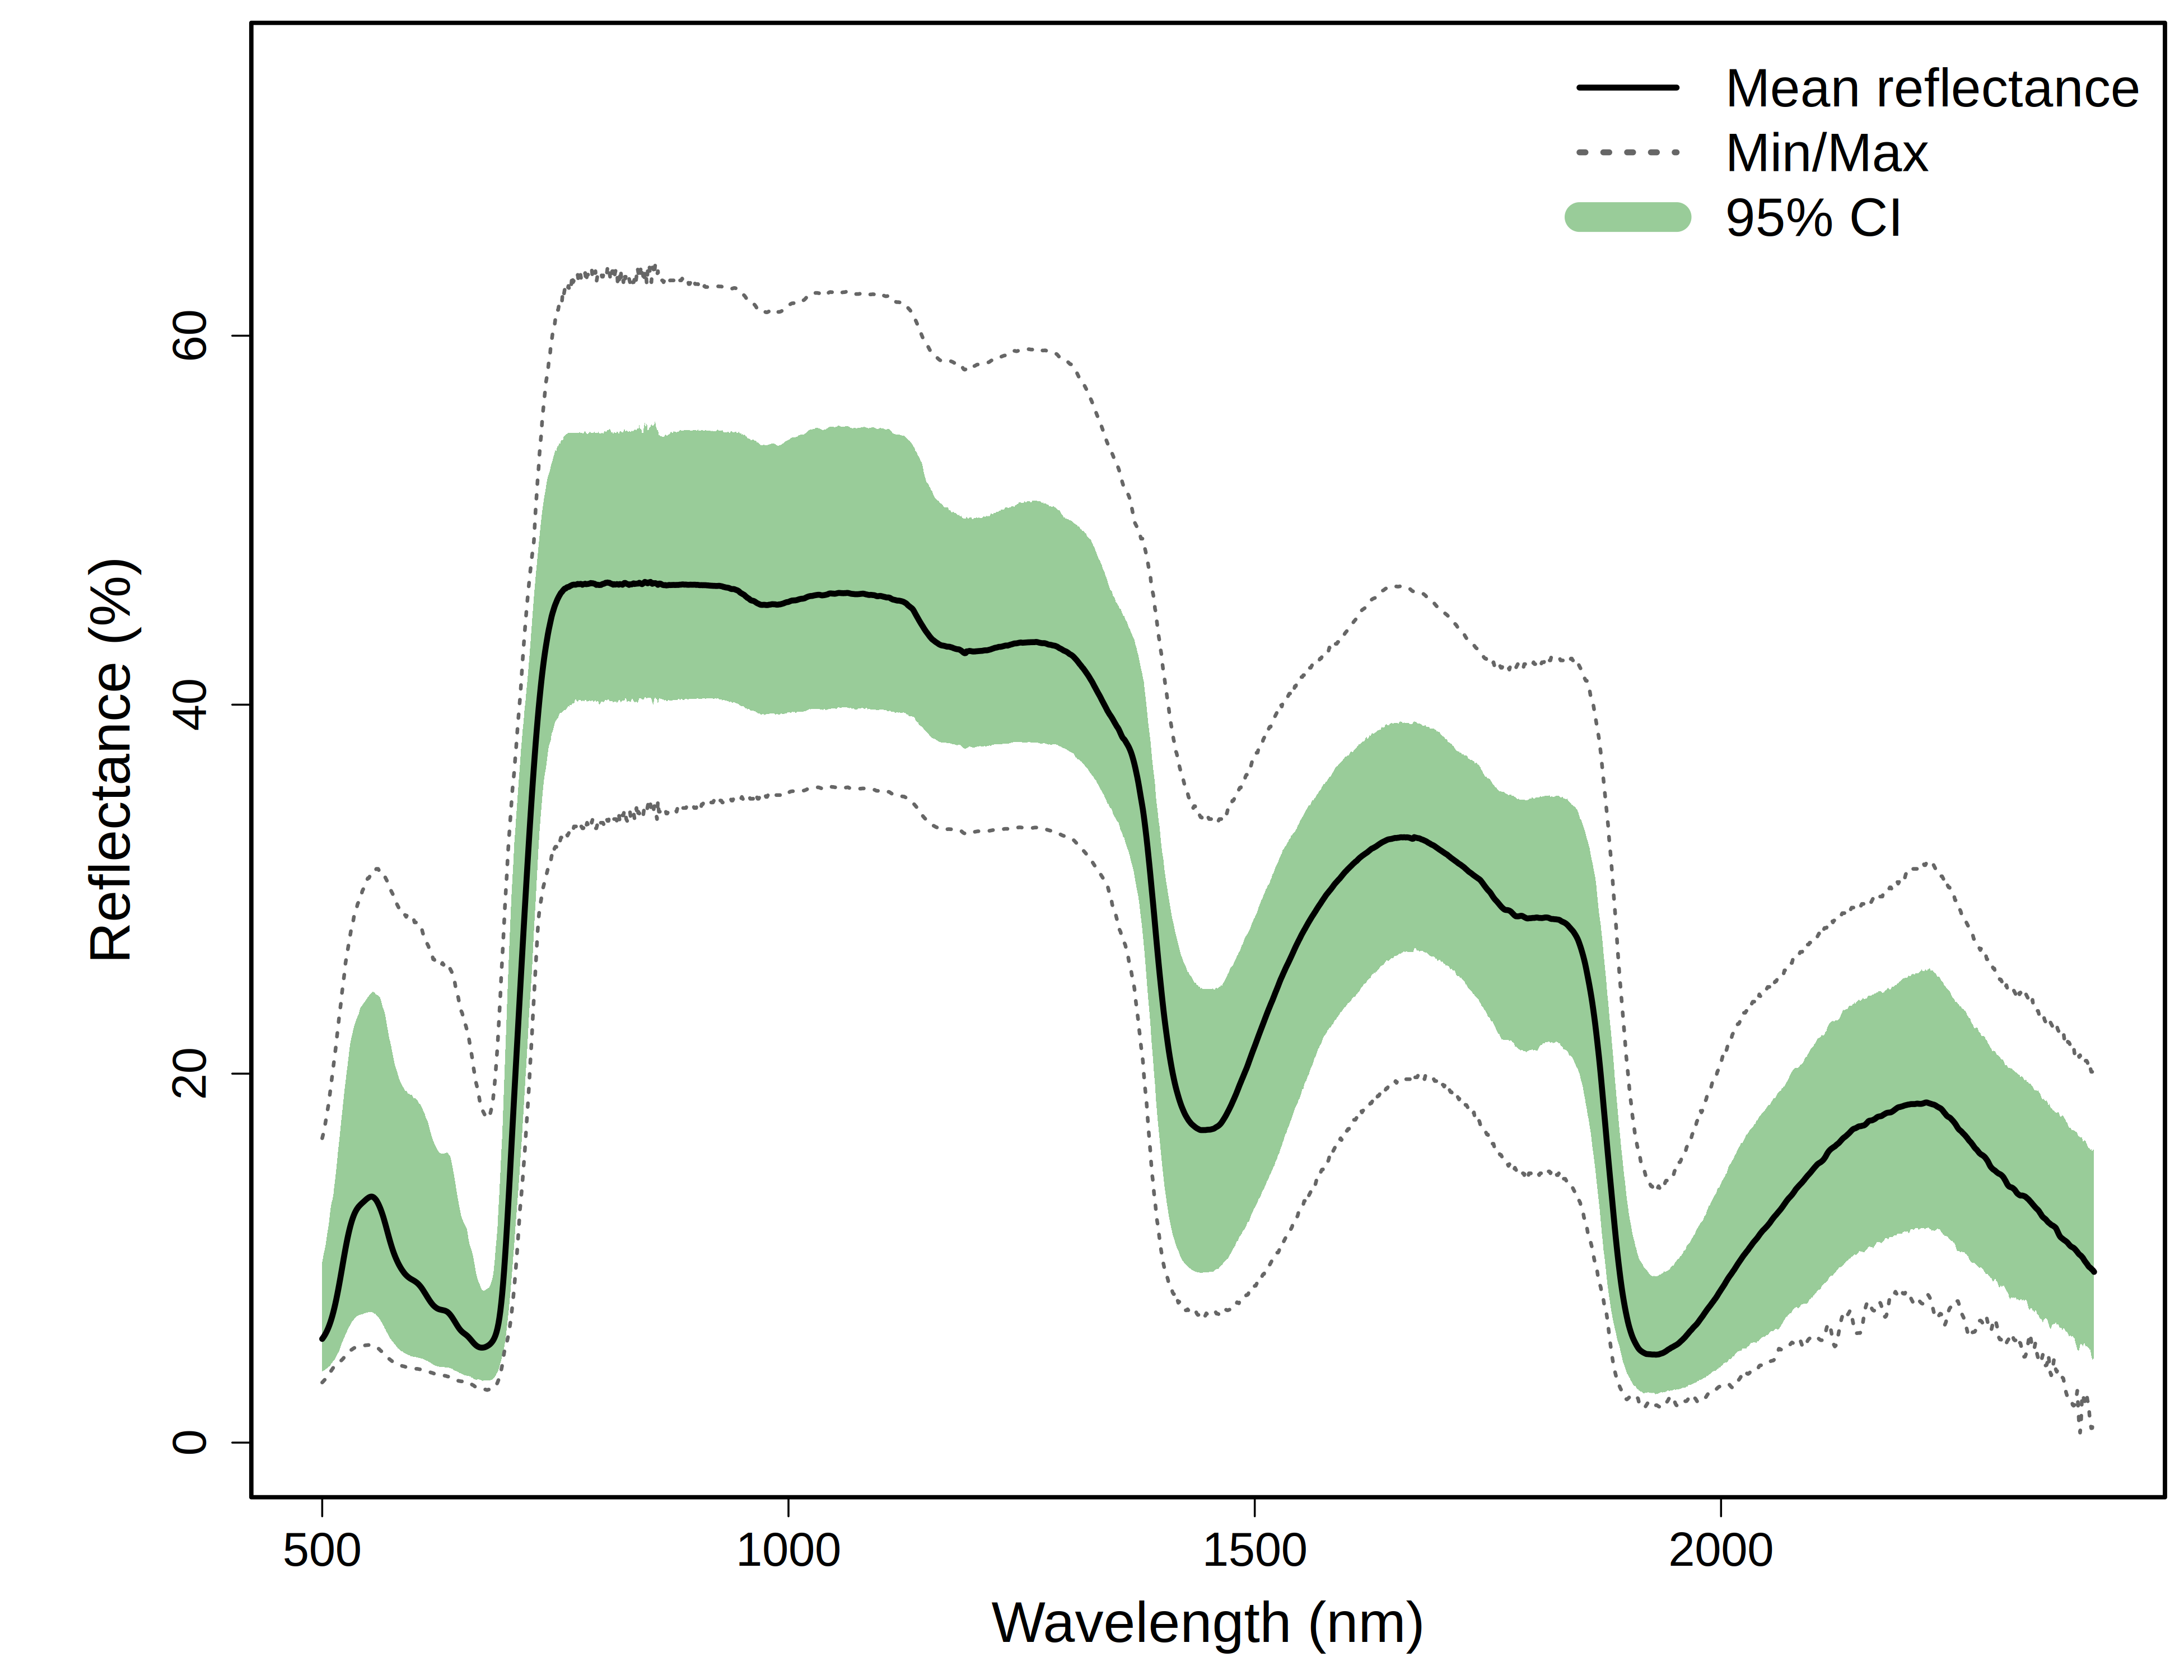

In [ ]:
run_r("05_spectra_plot.R", r'''
all_data <- readRDS("/content/all_data.rds")
wv <- 500:2400
spec_cols <- paste0("X", wv)
mean_spec <- colMeans(all_data[, spec_cols], na.rm = TRUE)
spectra_quantiles <- apply(all_data[, spec_cols], 2, quantile, na.rm = TRUE,
                           probs = c(0, 0.025, 0.05, 0.5, 0.95, 0.975, 1))
png("/content/spectra_summary.png", height = 3000, width = 3900, res = 340)
par(mfrow = c(1, 1), mar = c(4.5, 5.7, 0.3, 0.4), oma = c(0.3, 0.9, 0.3, 0.1))
plot(wv, mean_spec * 100, ylim = c(0, 74), cex = 0.00001, col = "white",
     xlab = "Wavelength (nm)", ylab = "Reflectance (%)", cex.axis = 1.5, cex.lab = 1.8)
polygon(c(wv, rev(wv)), c(spectra_quantiles[6, ] * 100, rev(spectra_quantiles[2, ] * 100)),
        col = "#99CC99", border = NA)
lines(wv, mean_spec * 100, lwd = 3, lty = 1, col = "black")
lines(wv, spectra_quantiles[1, ] * 100, lwd = 1.85, lty = 3, col = "grey40")
lines(wv, spectra_quantiles[7, ] * 100, lwd = 1.85, lty = 3, col = "grey40")
legend("topright", legend = c("Mean reflectance", "Min/Max", "95% CI"), lty = c(1, 3, 1),
       lwd = c(3, 3, 15), col = c("black", "grey40", "#99CC99"), bty = "n", cex = 1.7)
box(lwd = 2.2)
dev.off()
cat("wrote /content/spectra_summary.png\n")
''')
from IPython.display import Image, display
display(Image(filename="/content/spectra_summary.png"))

### Apply the 12-component LMA PLSR model with jackknife uncertainty

Follow the vignette's prediction steps exactly: row 1 of the coefficient table is the intercept; rows 2+ hold the
per-wavelength coefficients; predicted LMA = spectra matrix %*% coefficient vector + intercept. The jackknife
table is then applied iteration by iteration (its column 2 holds per-iteration intercepts, columns 3+ the
coefficient vectors) to derive per-sample 2.5%/97.5% quantiles and SD of predicted LMA. Units follow the
vignette: predictions are LMA in g m^-2 (the released coefficients are on the LMA scale; the vignette applies no
additional back-transform). Expected result: an output table with predictions and uncertainty columns, written
to CSV.

**日本語:** ビネットの予測手順(切片+波長係数の内積)とジャックナイフ不確実性の導出をそのまま実行します。
予測値の単位は g m^-2 です。

In [ ]:
run_r("06_predict.R", r'''
all_data <- readRDS("/content/all_data.rds")
ck <- readRDS("/content/plsr_coeffs.rds")
coeffs <- ck$coeffs
dims <- dim(coeffs)
LeafLMA.plsr.intercept <- coeffs[1, ]
coeffs <- data.frame(coeffs[2:dims[1], ])
names(coeffs) <- c("wavelength", "coefs")
coef_vec <- as.vector(coeffs[, 2])
sub_spec <- as.matrix(all_data[, paste0("X", 500:2400)])
temp <- sub_spec %*% coef_vec
leafLMA <- data.frame(rowSums(temp)) + LeafLMA.plsr.intercept[, 2]
leafLMA <- leafLMA[[1]]
names(leafLMA) <- "FS_PLSR_LMA_gDW_m2"
jk <- ck$jk
dims_jk <- dim(jk)
intercepts <- jk[, 2]
jk_est <- array(NA, dim = c(nrow(sub_spec), dims_jk[1]))
for (i in seq_len(dims_jk[1])) {
  coefs_i <- unlist(as.vector(jk[i, 3:dims_jk[2]]))
  jk_est[, i] <- rowSums(sub_spec %*% coefs_i) + intercepts[i]
}
jk_quant <- t(apply(jk_est, 1, quantile, probs = c(0.025, 0.975)))
out <- data.frame(all_data[, 1:4],
                  FS_PLSR_LMA_gDW_m2 = leafLMA,
                  FS_PLSR_Leaf_LMA_Sdev = apply(jk_est, 1, sd),
                  FS_PLSR_Leaf_LMA_L5 = jk_quant[, 1],
                  FS_PLSR_Leaf_LMA_U95 = jk_quant[, 2],
                  residual = leafLMA - all_data$LMA_gDW_m2)
write.csv(out, "/content/Angers_Lopex_PLSR_estimated_LMA_data.csv", row.names = FALSE)
saveRDS(out, "/content/lma_out.rds")
cat("output table dims (rows, cols):", dim(out), "\n")
''')

### Validation statistics: predicted vs observed LMA

Compute the vignette's fit statistics: RMSE from the residuals (predicted - observed) and R^2 from a linear
regression of predicted on observed LMA, exactly as the author script does. Then show a small inspectable table
of the first rows. Reference values printed in the author-rendered vignette: **RMSE = 19, R2 = 0.67** — compared
in the next cell.

**日本語:** RMSE(残差から)と R^2(予測値を観測値に回帰)をビネットと同じ定義で計算し、結果表の先頭を表示します。

In [ ]:
run_r("07_results.R", r'''
out <- readRDS("/content/lma_out.rds")
rmse <- sqrt(mean(out$residual^2))
reg <- lm(out$FS_PLSR_LMA_gDW_m2 ~ out$LMA_gDW_m2)
r2 <- summary(reg)$r.squared
cat(sprintf("RMSE = %.4g\nR2 = %.4g\nn = %d\n", rmse, r2, nrow(out)))
writeLines(sprintf("RMSE=%.6f\nR2=%.6f\nn=%d\n", rmse, r2, nrow(out)),
           "/content/lma_stats.txt")
''')
import pandas as pd
out = pd.read_csv("/content/Angers_Lopex_PLSR_estimated_LMA_data.csv")
display(out[["Dataset", "Sample_Num", "Common_Species_Name", "LMA_gDW_m2",
             "FS_PLSR_LMA_gDW_m2", "FS_PLSR_Leaf_LMA_Sdev",
             "FS_PLSR_Leaf_LMA_L5", "FS_PLSR_Leaf_LMA_U95"]].head(8))

,Dataset,Sample_Num,Common_Species_Name,LMA_gDW_m2,FS_PLSR_LMA_gDW_m2,FS_PLSR_Leaf_LMA_Sdev,FS_PLSR_Leaf_LMA_L5,FS_PLSR_Leaf_LMA_U95
0,Lopex,21,Garden lettuce,20.487805,45.820766,4.008956,38.463627,54.232467
1,Lopex,22,Garden lettuce,19.268293,52.679322,3.669800,46.542935,60.393636
2,Lopex,23,Garden lettuce,17.073171,43.472744,3.963848,35.835020,51.638805
3,Lopex,24,Garden lettuce,19.756098,36.788240,3.835530,30.046168,44.819247
4,Lopex,25,Garden lettuce,17.317073,27.184844,3.957899,19.955307,35.259605
5,Lopex,171,Corn,36.585366,62.899299,3.310405,55.333419,68.416281
6,Lopex,172,Corn,41.951220,60.720025,4.634121,51.143939,68.709452
7,Lopex,173,Corn,31.707317,48.047520,4.365129,38.747272,55.789872


### Validation plot — observed vs jackknife-predicted LMA (vignette's final figure)

Reproduce the author's validation figure with `plotrix::plotCI`: predicted LMA on the x axis with horizontal
jackknife 95% error bars, observed LMA on the y axis, 1:1 line, RMSE and R^2 in the legend. The only change from
the original is the point fill: `scales::alpha("grey70", 0.7)` is replaced by the equivalent explicit RGBA color
`#B3B3B3B3`. This saved PNG is the notebook's representative output.

**日本語:** `plotCI` でビネット最終図(予測値 x 軸+ジャックナイフ 95% エラーバー、観測値 y 軸、1:1 直線)を再現します。

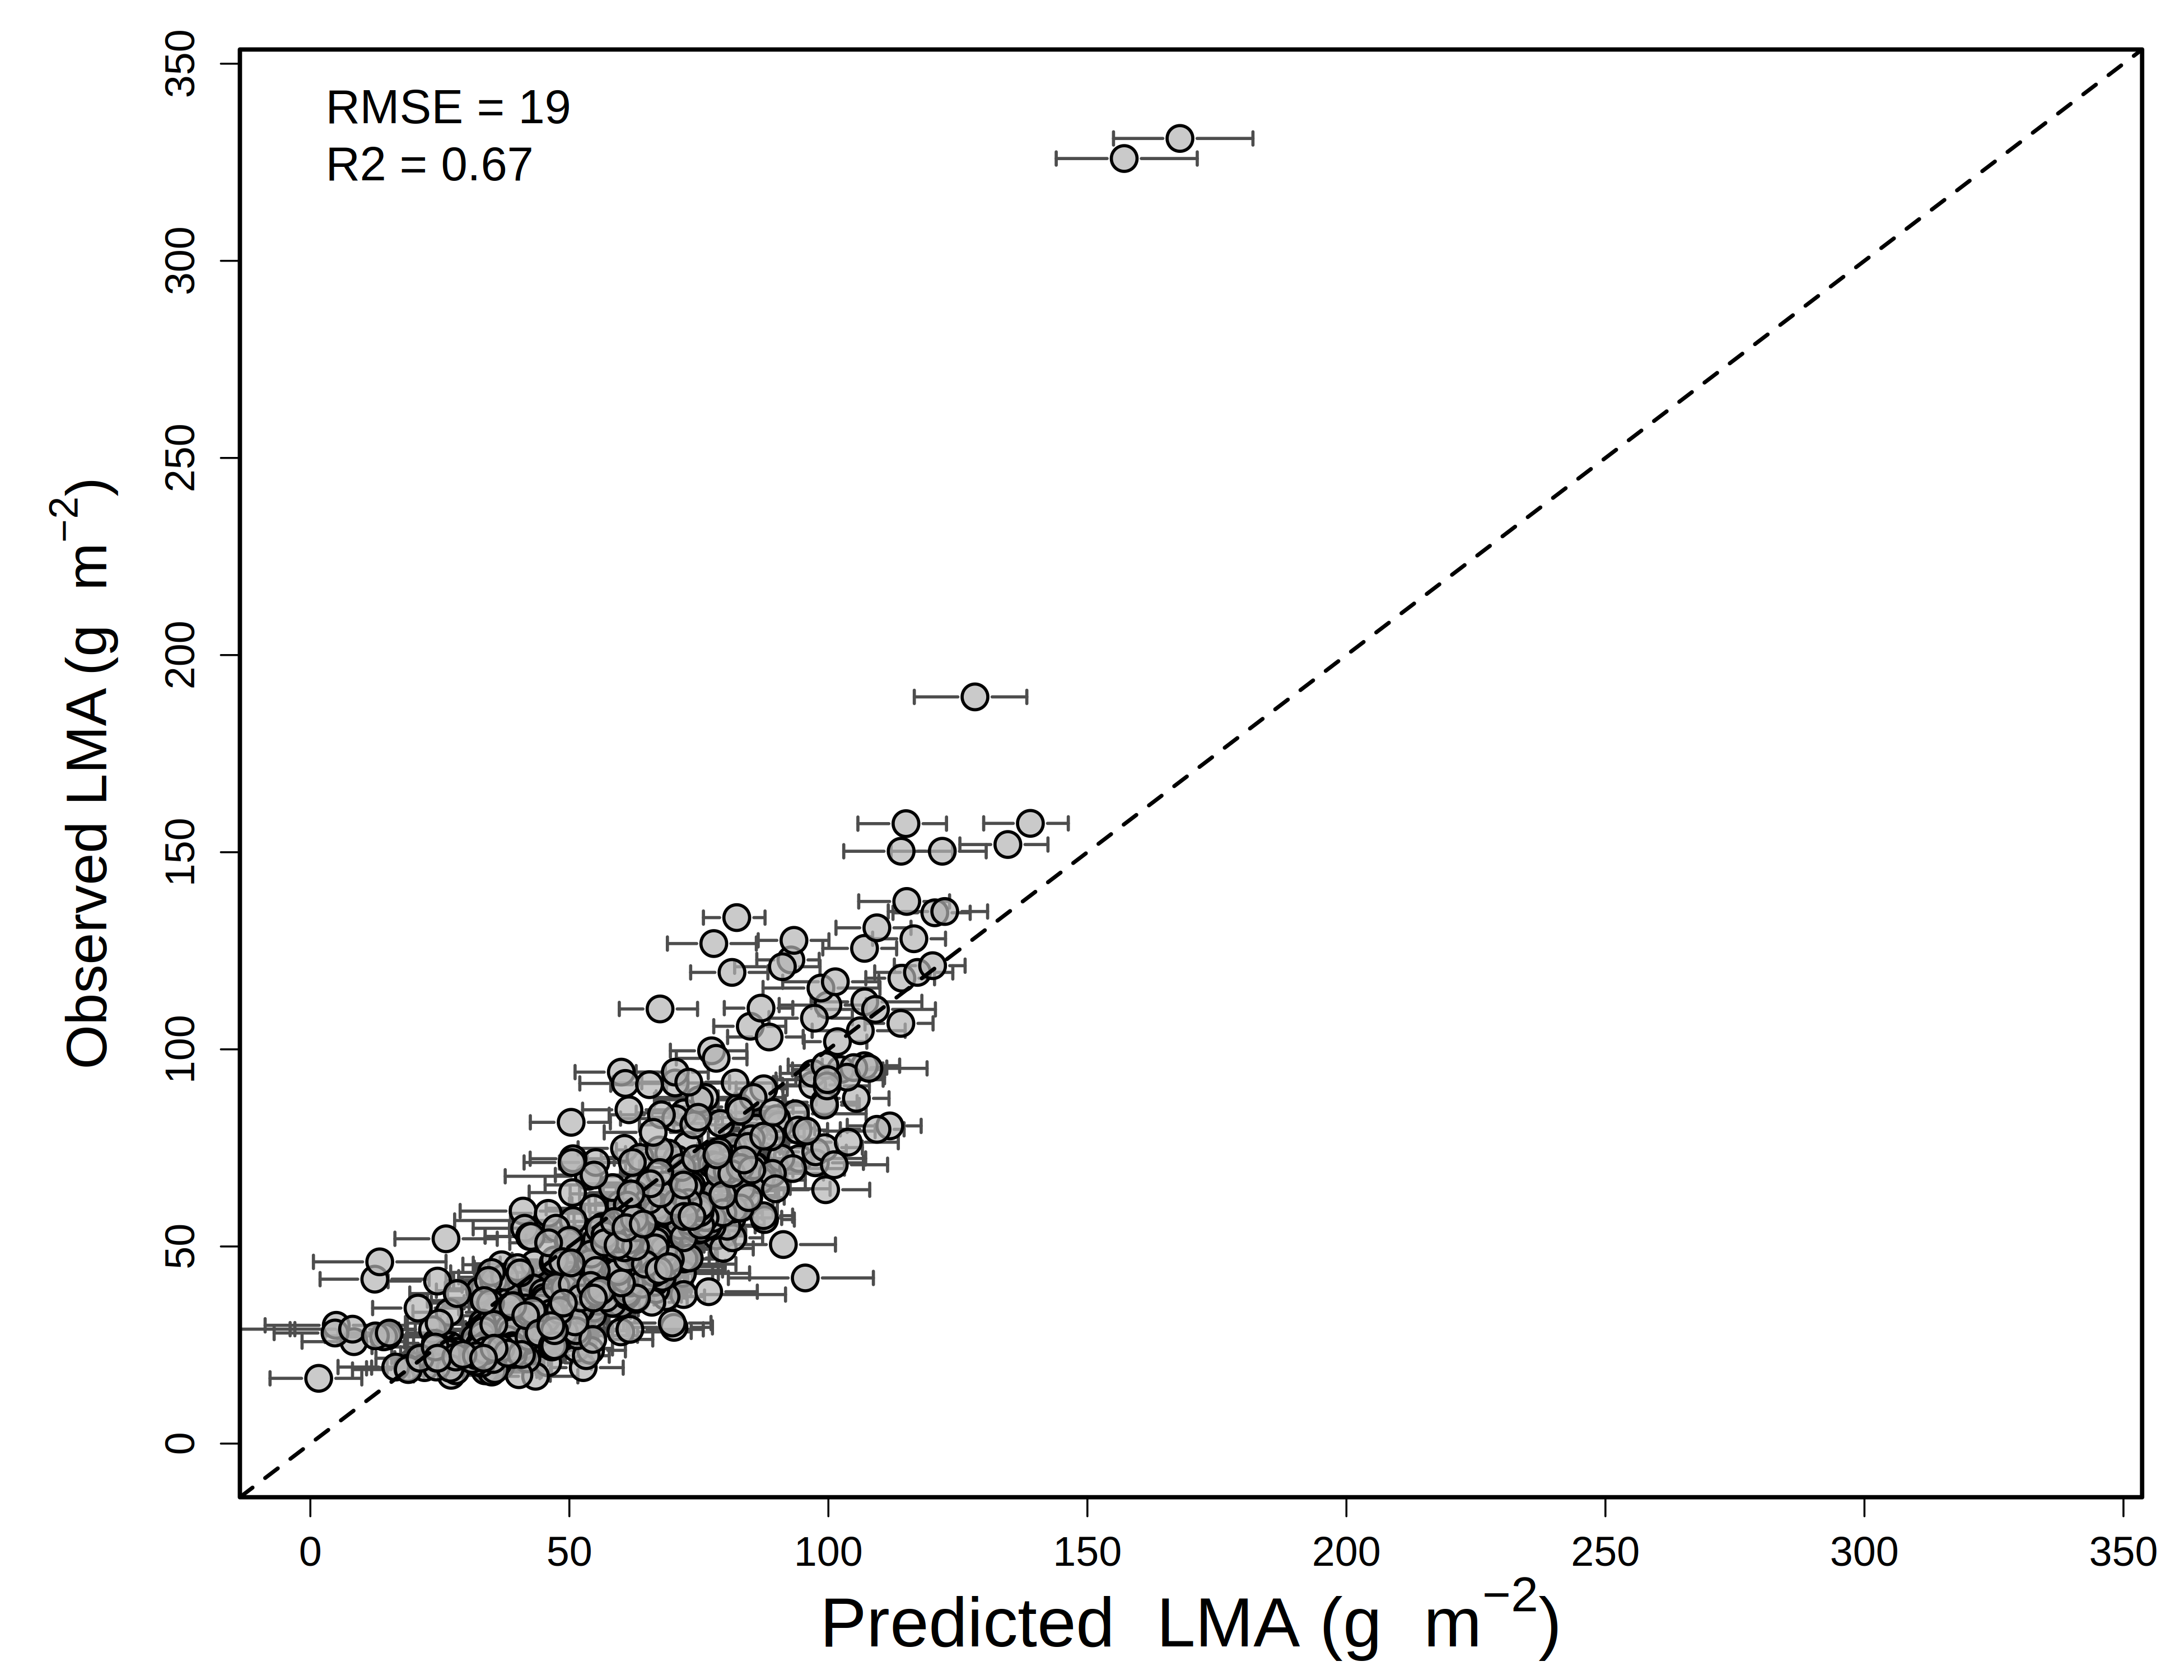

In [ ]:
run_r("08_validation_plot.R", r'''
out <- readRDS("/content/lma_out.rds")
library(plotrix)
rmse <- sqrt(mean(out$residual^2))
reg <- lm(out$FS_PLSR_LMA_gDW_m2 ~ out$LMA_gDW_m2)
png("/content/lma_validation_plot.png", height = 3000, width = 3900, res = 340)
par(mfrow = c(1, 1), mar = c(4.5, 5.4, 1, 1), oma = c(0.3, 0.9, 0.3, 0.1))
plotCI(out$FS_PLSR_LMA_gDW_m2, out$LMA_gDW_m2, li = out$FS_PLSR_Leaf_LMA_L5,
       ui = out$FS_PLSR_Leaf_LMA_U95, gap = 0.009, sfrac = 0.004, lwd = 1.6,
       err = "x", pch = 21, col = "black", pt.bg = "#B3B3B3B3", scol = "grey30",
       xlim = c(0, 340), cex = 1.8, ylim = c(0, 340), xlab = "",
       ylab = expression(paste("Observed LMA (", g ~ m^{-2}, ")")), main = "",
       cex.axis = 1.3, cex.lab = 1.8)
mtext(side = 1, text = expression(paste(Predicted ~ LMA, " (", g ~ m^{-2}, ")")),
      line = 3.5, cex = 2.2)
abline(0, 1, lty = 2, lwd = 2)
legend("topleft", legend = c(paste0("RMSE = ", round(rmse)),
       paste0("R2 = ", round(summary(reg)$r.squared, 2))), bty = "n", cex = 1.5)
box(lwd = 2.2)
dev.off()
cat("wrote /content/lma_validation_plot.png\n")
''')
from IPython.display import Image, display
display(Image(filename="/content/lma_validation_plot.png"))

### Comparison with the author's published vignette result

The author-rendered vignette reports **RMSE = 19** and **R2 = 0.67** for this same application (LOPEX93 + Angers
fresh-leaf spectra, 12-component LMA model). This cell asserts that the reproduction lands on those values within
a small tolerance (rounding in the published figure plus ordinary cross-platform numeric noise; the PLSR itself is
deterministic given fixed coefficients and inputs, so differences should be tiny).

**日本語:** 著者ビネットの公開値(RMSE = 19, R2 = 0.67)と本実行結果を照合します。

In [ ]:
stats = {}
for line in open("/content/lma_stats.txt"):
    if "=" in line:
        k, v = line.strip().split("=", 1)
        stats[k] = float(v)
rmse, r2 = stats["RMSE"], stats["R2"]
print(f"reproduced: RMSE = {rmse:.4g}, R2 = {r2:.4g} (n = {int(stats['n'])})")
print("author vignette reference: RMSE = 19, R2 = 0.67")
assert abs(rmse - 19) <= 1.0, f"RMSE {rmse:.3f} deviates from the vignette reference 19 by more than 1"
assert abs(r2 - 0.67) <= 0.02, f"R2 {r2:.3f} deviates from the vignette reference 0.67 by more than 0.02"
print("PASS: reproduction matches the author vignette reference within tolerance")

reproduced: RMSE = 19.36, R2 = 0.6742 (n = 579)
author vignette reference: RMSE = 19, R2 = 0.67
PASS: reproduction matches the author vignette reference within tolerance


## Interpretation, scope, and validation record

**What this demonstrates:** the authors' released 12-component LMA PLSR model transfers to two independent
public leaf-spectra packages (LOPEX93, Angers) exactly as shown in their vignette: predicted LMA tracks observed
LMA (g m^-2) with jackknife-derived uncertainty, matching the vignette's own RMSE/R2. This is a **partial
demonstration** — the paper's multi-trait models (C, N, C:N, sugars, amino acids), its own eight-species
sampling/validation design, and dataset-level accuracy claims are out of scope here. The paywalled full text was
not needed for this scope.

**Documented adaptations (numerics unchanged):** base-R `read.csv`/`download.file` instead of `readr`/`httr`;
explicit RGBA `#B3B3B3B3` instead of `scales::alpha("grey70", 0.7)`; columns resolved by name prefix because the
original backtick-quoted names (`Sample_#`, `Leaf mass per area (g/cm2)`) are mangled identically by base R's
`check.names=TRUE` (`English.Name`, `Sample_.`, `Leaf.mass.per.area..g.cm..`). The Angers LMA column is matched
by the `Leaf.mass.per.area` prefix (the PDF rendering of the vignette shows the superscript ambiguously).
Everything else follows the vignette line by line.

**Validation record:** fully executed top-to-bottom on a fresh Colab **CPU** runtime (Python kernel launching
`Rscript`) on 2026-10-27; emitted outputs archived with the run. Free-tier runtimes may differ in speed.

**日本語:** 本ノートブックは著者公開モデルの部分再現(LMA のみ)であり、論文の全性状・データセット規模の検証では
ありません。数値適応箇所は上記の通りで、計算内容はビネットと同一です。2026-10-27 に新規 CPU ランタイムで
全体実行を検証済みです。

**References**
- Ely et al. 2019, J Exp Bot 70(6):1789-1799, DOI 10.1093/jxb/erz061 (supplement: `erz061_suppl_supplementary_table_s1_and_figure_s1-s2.pdf` in the author repo).
- Author code/vignette: `TESTgroup-BNL/Ely_etal_2019_JournalOfExperimentalBotany` @ `44face179c5cf17dddd5d7b7487ed0a1485e65f9` (GPL-3.0).
- EcoSIS LOPEX93 (`13aef0ce-dd6f-4b35-91d9-28932e506c41`) and Angers (`2231d4f6-981e-4408-bf23-1b2b303f475e`) packages.